### Importation des outils nécessaires

In [1]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

/Users/madina/uplifting/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Préparation des bibliothèques d’analyse

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

### Téléchargement et exploration des fichiers du jeu de données

In [3]:
path = kagglehub.dataset_download(
    "bofulee/kevin-hillstrom-minethatdata-e-mailanalytics"
)

print("Dossier :", path)

print("Fichiers :")
for f in os.listdir(path):
    print(f)

Dossier : /Users/madina/.cache/kagglehub/datasets/bofulee/kevin-hillstrom-minethatdata-e-mailanalytics/versions/1
Fichiers :
Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv


### Chargement du jeu de données dans un df

In [4]:


df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "bofulee/kevin-hillstrom-minethatdata-e-mailanalytics",
    "Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv"
)

print(df.head())

   recency history_segment  history  mens  womens   zip_code  newbie channel  \
0       10  2) $100 - $200   142.44     1       0  Surburban       0   Phone   
1        6  3) $200 - $350   329.08     1       1      Rural       1     Web   
2        7  2) $100 - $200   180.65     0       1  Surburban       1     Web   
3        9  5) $500 - $750   675.83     1       0      Rural       1     Web   
4        2    1) $0 - $100    45.34     1       0      Urban       0     Web   

         segment  visit  conversion  spend  
0  Womens E-Mail      0           0    0.0  
1      No E-Mail      0           0    0.0  
2  Womens E-Mail      0           0    0.0  
3    Mens E-Mail      0           0    0.0  
4  Womens E-Mail      0           0    0.0  


### Aperçu des dernières lignes du jeu de données

In [5]:
print(df.tail())

       recency history_segment  history  mens  womens   zip_code  newbie  \
63995       10  2) $100 - $200   105.54     1       0      Urban       0   
63996        5    1) $0 - $100    38.91     0       1      Urban       1   
63997        6    1) $0 - $100    29.99     1       0      Urban       1   
63998        1  5) $500 - $750   552.94     1       0  Surburban       1   
63999        1  4) $350 - $500   472.82     0       1  Surburban       0   

            channel        segment  visit  conversion  spend  
63995           Web    Mens E-Mail      0           0    0.0  
63996         Phone    Mens E-Mail      0           0    0.0  
63997         Phone    Mens E-Mail      0           0    0.0  
63998  Multichannel  Womens E-Mail      0           0    0.0  
63999           Web    Mens E-Mail      0           0    0.0  


In [7]:
print(df[5:10])

   recency history_segment  history  mens  womens   zip_code  newbie channel  \
5        6  2) $100 - $200   134.83     0       1  Surburban       0   Phone   
6        9  3) $200 - $350   280.20     1       0  Surburban       1   Phone   
7        9    1) $0 - $100    46.42     0       1      Urban       0   Phone   
8        9  5) $500 - $750   675.07     1       1      Rural       1   Phone   
9       10    1) $0 - $100    32.84     0       1      Urban       1     Web   

         segment  visit  conversion  spend  
5  Womens E-Mail      1           0    0.0  
6  Womens E-Mail      0           0    0.0  
7  Womens E-Mail      0           0    0.0  
8    Mens E-Mail      0           0    0.0  
9  Womens E-Mail      0           0    0.0  


### Exploration de la structure et des colonnes

In [8]:
df.shape
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  str    
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  str    
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  str    
 8   segment          64000 non-null  str    
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), str(4)
memory usage: 5.9 MB


### Statistiques descriptives

In [9]:
df.describe()

,recency,history,mens,womens,newbie,visit,conversion,spend
count,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000
mean,5.763734,242.085656,0.551031,0.549719,0.502250,0.146781,0.009031,1.050908
std,3.507592,256.158608,0.497393,0.497526,0.499999,0.353890,0.094604,15.036448
min,1.000000,29.990000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,64.660000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,6.000000,158.110000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
75%,9.000000,325.657500,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
max,12.000000,3345.930000,1.000000,1.000000,1.000000,1.000000,1.000000,499.000000


### Vérification des valeurs manquantes

In [10]:
df.isnull().sum()

recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

### Répartition des valeurs de dépenses

In [12]:
df["spend"].value_counts()

spend
0.00      63422
29.99       136
499.00       12
362.20        2
83.26         2
          ...  
117.84        1
90.57         1
113.44        1
99.49         1
154.20        1
Name: count, Length: 429, dtype: int64

In [5]:
print("\nColumns:", df.columns.tolist())
print("\nSegment distribution:")
print(df['segment'].value_counts())
print("\nConversion rate overall:")
print(df['conversion'].value_counts(normalize=True).mul(100).round(2))


Columns: ['recency', 'history_segment', 'history', 'mens', 'womens', 'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend']

Segment distribution:
segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

Conversion rate overall:
conversion
0    99.1
1     0.9
Name: proportion, dtype: float64


### Répartition des utilisateurs par groupe expérimental

In [14]:
df['segment'].value_counts(normalize=True)*100

segment
Womens E-Mail    33.417187
Mens E-Mail      33.292187
No E-Mail        33.290625
Name: proportion, dtype: float64

#### les groupes sont bien equilibrés, chacun represent environ un tiers des utilisateurs. Le groupe de Womens E-Mail est legerement plus representé (+0.12%), mais cette difference n'est pas importante et donc ne devrait pas introduire de biais significatif dans l'analyse. 

### Calcul du taux de conversion par groupe

In [15]:
conversion_rate = (
    df.groupby('segment')['conversion']
    .mean()
    .sort_values(ascending=False)
)

conversion_rate*100

segment
Mens E-Mail      1.253109
Womens E-Mail    0.883714
No E-Mail        0.572609
Name: conversion, dtype: float64

#### L'analyse de taux de conversion montre que les campagnes mails representent taux d'achat plus eleves par rapport au groupe de controle. Ces resultats suggerent un impact positif potentiel les emails sur les achats. Je vais faire ensuite une test statistique pour confirmer si ces diffences sont significatives.

Une analyse exploratoire suggère que la campagne « Mens E-Mail » a enregistré le taux de conversion le plus élevé parmi les groupes d'expérimentation. 

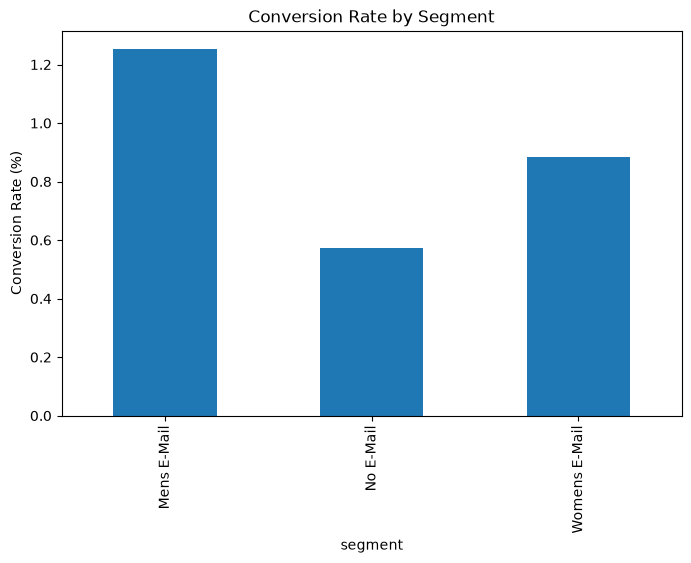

In [ ]:
(df.groupby('segment')['conversion'].mean()*100).plot(
    kind='bar',
    figsize=(8,5)
)

plt.ylabel("Conversion Rate (%)")
plt.title("Conversion Rate by Segment")
plt.show()

### Quel group genere plus de revenu ?


In [17]:
spend_analysis = df.groupby('segment')['spend'].agg(
    ['mean','sum']
)

spend_analysis

,mean,sum
segment,,
Mens E-Mail,1.422617,30311.69
No E-Mail,0.652789,13908.33
Womens E-Mail,1.077202,23038.11


L'analyse de revenus montre que les groupes de traitement generent davantage de revenus. Ces resultats suggerent un impact positives sur les depenses clients, avec une meuilleure performance pour la cmpagne Mens Email. Les test statistiques seront effectues pour confirmer les impacts.

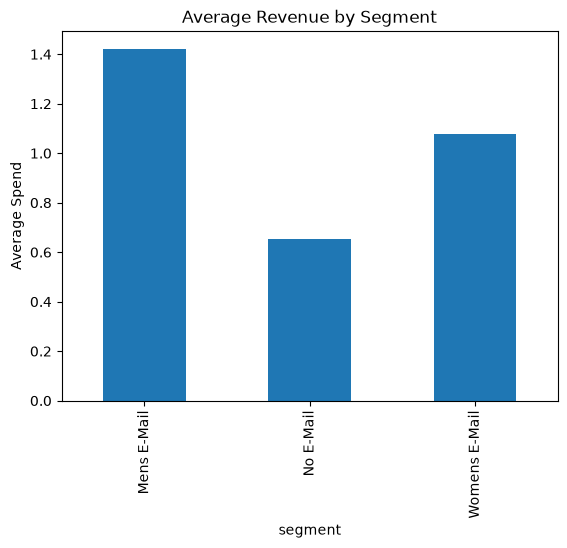

In [18]:
df.groupby('segment')['spend'].mean().plot(
    kind='bar'
)

plt.ylabel("Average Spend")
plt.title("Average Revenue by Segment")
plt.show()

### Comparer email vs no-email

In [20]:
control = df[df.segment=="No E-Mail"]['conversion'].mean()

treatment = df[df.segment!="No E-Mail"]['conversion'].mean()

lift = (treatment-control)/control

print(lift)

0.865263057656967


#### les clients ayant recu mails ont taux de conversion environ 87% superieur au groupe n'ayant pas recu les mails.

### Quelle type email fonctionne mieux?

In [21]:
df.groupby('segment')[['conversion','spend']].mean()

,conversion,spend
segment,,
Mens E-Mail,0.012531,1.422617
No E-Mail,0.005726,0.652789
Womens E-Mail,0.008837,1.077202


#### En regardant les chiffres, le groupe de traitement ont des meilleures performances que le groupe de controle. Cela montre que les campaignes mails ont  un impact positif sur l'engagement de client, avec une efficacite particulierement elevee pour la campagne Mens Email.

### Les nouveaux clients sont-ils plus sensibles aux emails ?

In [22]:
df.groupby(
    ['segment','newbie']
)['conversion'].mean()

segment        newbie
Mens E-Mail    0         0.013935
               1         0.011136
No E-Mail      0         0.007728
               1         0.003740
Womens E-Mail  0         0.008660
               1         0.009012
Name: conversion, dtype: float64

Les nouveaux clients semblent bénéficier davantage des campagnes email que lorsqu'ils ne reçoivent aucun email. En particulier, leur taux de conversion est nettement supérieur dans les groupes de traitement que dans le groupe contrôle. Toutefois, seule la campagne Womens E-Mail présente un taux de conversion légèrement supérieur chez les nouveaux clients par rapport aux anciens.

### Les gros clients repondent mieux?

In [23]:
df.groupby(
    ['segment','history_segment']
)['conversion'].mean()

segment        history_segment 
Mens E-Mail    1) $0 - $100        0.009192
               2) $100 - $200      0.008953
               3) $200 - $350      0.015403
               4) $350 - $500      0.020029
               5) $500 - $750      0.013776
               6) $750 - $1,000    0.024845
               7) $1,000 +         0.023707
No E-Mail      1) $0 - $100        0.004204
               2) $100 - $200      0.004136
               3) $200 - $350      0.006924
               4) $350 - $500      0.011299
               5) $500 - $750      0.005448
               6) $750 - $1,000    0.004823
               7) $1,000 +         0.014423
Womens E-Mail  1) $0 - $100        0.007991
               2) $100 - $200      0.007827
               3) $200 - $350      0.006258
               4) $350 - $500      0.009141
               5) $500 - $750      0.015644
               6) $750 - $1,000    0.013491
               7) $1,000 +         0.025701
Name: conversion, dtype: float64

Les segments avec historique d'achat élevé (750$+ ou 1000$)affichent parmi les meuilleurs taux de conversion, surtout dans les groupent ayant reçu email.

Le groupe Mens E-mail obtient les meuilleurs resultats pour plusieurs segments intermediares et eleves, par contre le groupe Womens E-mail montrent les meuilleures resultats que quand les clients depensent plus de 1000$.

### Le canal influence-t-il la performance ?

In [24]:
df.groupby(
    ['segment','channel']
)['conversion'].mean()

segment        channel     
Mens E-Mail    Multichannel    0.017074
               Phone           0.010823
               Web             0.012961
No E-Mail      Multichannel    0.006907
               Phone           0.005361
               Web             0.005761
Womens E-Mail  Multichannel    0.013959
               Phone           0.007087
               Web             0.009194
Name: conversion, dtype: float64

L'analyse montre que le canal d'acquisition influence les performances de la campagne. Les clients provenant du canal Multichannel présentent systématiquement les taux de conversion les plus élevés, aussi bien dans les groupes de traitement que dans le groupe contrôle.